In [14]:

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from tqdm.auto import tqdm
from pathlib import Path

In [15]:

# GPU or CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [16]:
# Project directories
cwd = Path.cwd()
project_dir = cwd.parent if cwd.name == "notebooks" else cwd
results_dir = project_dir / "results"
results_dir.mkdir(parents=True, exist_ok=True)

In [17]:
# Dataset
transform = transforms.ToTensor()
full_trainset = datasets.MNIST(
    root=str(project_dir / "data"),
    train=True, download=True, transform=transform
)

testset = datasets.MNIST(
    root=str(project_dir / "data"),
    train=False, download=True, transform=transform
)

trainset, valset = random_split(
    full_trainset, [50000, 10000],
    generator=torch.Generator().manual_seed(42)
)

batch_size = 64

trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True)
valloader = DataLoader(valset, batch_size=batch_size, shuffle=False)
testloader = DataLoader(testset, batch_size=batch_size, shuffle=False)

print("Training:", len(trainset))
print("Validation:", len(valset))
print("Testing:", len(testset))

Training: 50000
Validation: 10000
Testing: 10000


In [18]:

class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5),
            nn.Tanh(),
            nn.AvgPool2d(2),

            nn.Conv2d(6, 16, kernel_size=5),
            nn.Tanh(),
            nn.AvgPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 4 * 4, 120),
            nn.Tanh(),
            nn.Linear(120, 84),
            nn.Tanh(),
            nn.Linear(84, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

lenet = LeNet5().to(device)
print(lenet)


LeNet5(
  (features): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
    (1): Tanh()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Tanh()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=256, out_features=120, bias=True)
    (2): Tanh()
    (3): Linear(in_features=120, out_features=84, bias=True)
    (4): Tanh()
    (5): Linear(in_features=84, out_features=10, bias=True)
  )
)


In [19]:

class ModernCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 3 * 3, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

modern_cnn = ModernCNN().to(device)
print(modern_cnn)


ModernCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1152, out_features=128, bias=True

In [20]:

def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, 100 * correct / total


In [21]:

def train_model(model, epochs=10):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    for epoch in range(epochs):
        model.train()

        running_loss = 0
        correct = 0
        total = 0

        progress = tqdm(
            trainloader,
            desc=f"Epoch {epoch+1}/{epochs}",
            leave=True,
            ascii=" ━",
            bar_format="{desc} {bar:32} {percentage:3.0f}%"
        )

        for images, labels in progress:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = 100 * correct / total

        # Validation after each epoch
        val_loss, val_acc = evaluate(model, valloader, criterion)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.2f}%"
        )

    return history


In [22]:

torch.manual_seed(42)
lenet = LeNet5().to(device)

print("Training LeNet-5")
lenet_history = train_model(lenet, epochs=10)

torch.manual_seed(42)
modern_cnn = ModernCNN().to(device)

print("\nTraining Modern CNN")
modern_history = train_model(modern_cnn, epochs=10)


Training LeNet-5


Epoch 1/10                                    0%

Train Loss: 0.3429 | Train Acc: 90.11% | Val Loss: 0.1387 | Val Acc: 95.91%


Epoch 2/10                                    0%

Train Loss: 0.1012 | Train Acc: 96.88% | Val Loss: 0.0883 | Val Acc: 97.28%


...

Train Loss: 0.0219 | Train Acc: 99.33% | Val Loss: 0.0378 | Val Acc: 99.02%


Epoch 9/10                                    0%

Train Loss: 0.0200 | Train Acc: 99.35% | Val Loss: 0.0371 | Val Acc: 99.12%


Epoch 10/10                                    0%

Train Loss: 0.0210 | Train Acc: 99.41% | Val Loss: 0.0356 | Val Acc: 99.22%


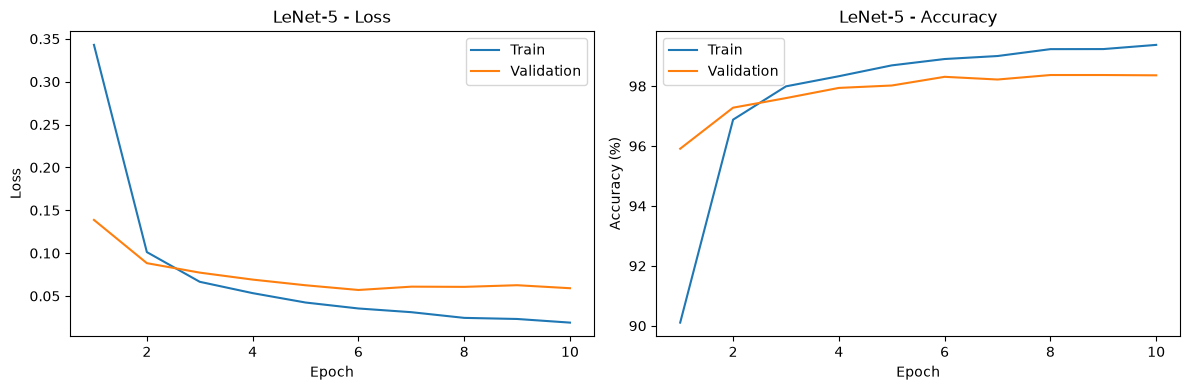

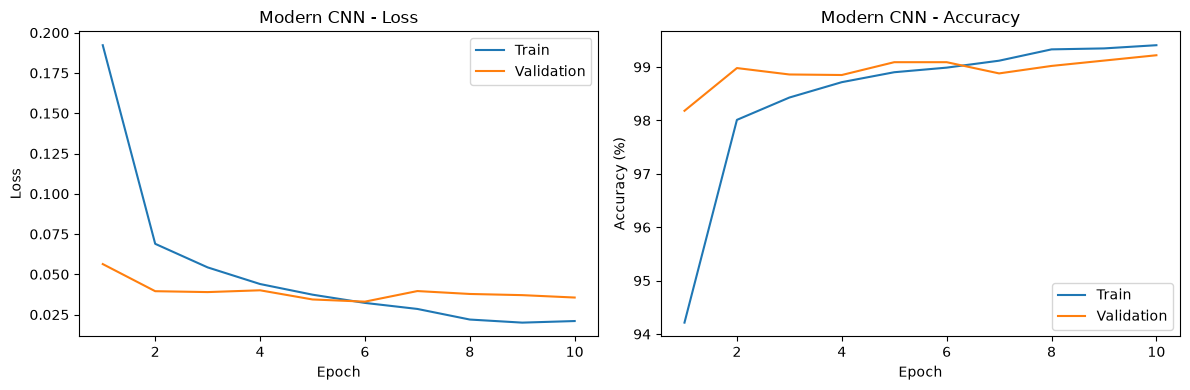

In [23]:

def plot_history(history, model_name, filename):
    epochs = range(1, 11)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs, history["train_loss"], label="Train")
    axes[0].plot(epochs, history["val_loss"], label="Validation")
    axes[0].set_title(model_name + " - Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    axes[1].plot(epochs, history["train_acc"], label="Train")
    axes[1].plot(epochs, history["val_acc"], label="Validation")
    axes[1].set_title(model_name + " - Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy (%)")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(results_dir / filename, dpi=300)
    plt.show()


plot_history(lenet_history, "LeNet-5", "Q2_LeNet5_Curves.png")
plot_history(modern_history, "Modern CNN", "Q2_ModernCNN_Curves.png")


In [24]:

criterion = nn.CrossEntropyLoss()

lenet_train_loss, lenet_train_acc = evaluate(lenet, trainloader, criterion)
lenet_test_loss, lenet_test_acc = evaluate(lenet, testloader, criterion)

modern_train_loss, modern_train_acc = evaluate(modern_cnn, trainloader, criterion)
modern_test_loss, modern_test_acc = evaluate(modern_cnn, testloader, criterion)

print("FINAL RESULTS AFTER 10 EPOCHS")
print("-" * 55)

print(f"LeNet-5    | Train: {lenet_train_acc:.2f}% | Test: {lenet_test_acc:.2f}%")
print(f"Modern CNN | Train: {modern_train_acc:.2f}% | Test: {modern_test_acc:.2f}%")


FINAL RESULTS AFTER 10 EPOCHS
-------------------------------------------------------
LeNet-5    | Train: 99.58% | Test: 98.62%
Modern CNN | Train: 99.82% | Test: 99.23%


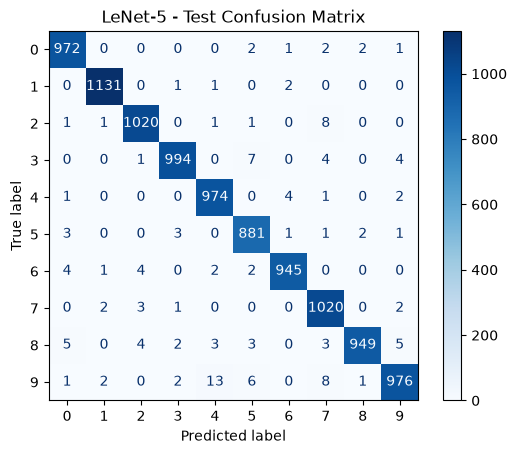

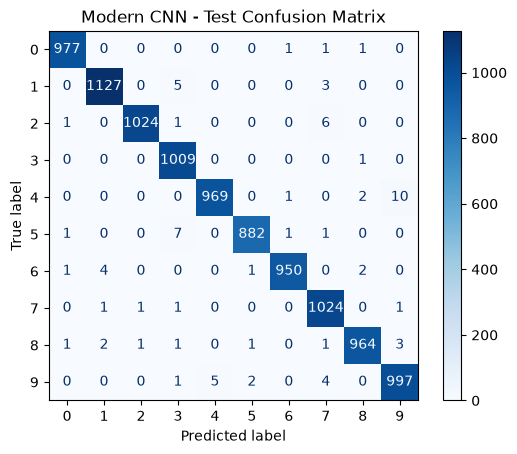

In [25]:

def plot_confusion_matrix(model, model_name, filename):
    model.eval()

    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in testloader:
            images = images.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            all_labels.extend(labels.numpy())
            all_predictions.extend(predictions.cpu().numpy())

    cm = confusion_matrix(
        all_labels, all_predictions, labels=range(10)
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=list(range(10))
    )

    disp.plot(cmap="Blues", values_format="d")
    plt.title(model_name + " - Test Confusion Matrix")
    plt.savefig(results_dir / filename, dpi=300)
    plt.show()


plot_confusion_matrix(
    lenet, "LeNet-5", "Q2_LeNet5_Confusion.png"
)

plot_confusion_matrix(
    modern_cnn, "Modern CNN", "Q2_ModernCNN_Confusion.png"
)
